<a href="https://colab.research.google.com/github/EsatovinVictoria/ML_Semester5_EsatovinEbenhaezerVictoria/blob/main/Pertemuan_6/Praktikum_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 1

In [1]:
!pip install annoy

Exact NN index: [ 42   9 849]
Exact NN jarak: [0. 2. 2.]
Waktu Exact: 1.8086 ms

Annoy NN index: [42, 9, 144]
Annoy NN jarak: [np.float32(0.0), np.float32(2.0), np.float32(2.0)]
Waktu Annoy: 0.2129 ms


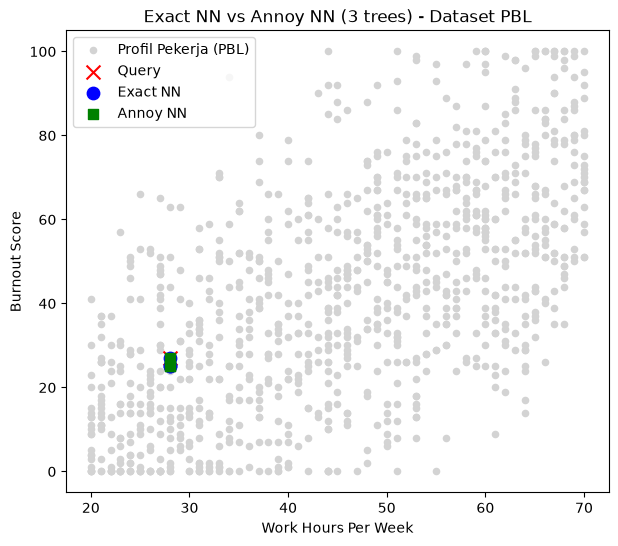

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
from annoy import AnnoyIndex

# 1. Dataset 2D dari Dataset PBL
df = pd.read_csv('burnout_dataset1.csv')
features_2d = ['Work_Hours_Per_Week', 'Burnout_Score']
df_2d = df[features_2d].fillna(df[features_2d].mean(numeric_only=True))

# Ambil sampel 1000 data agar visualisasi jelas dan representatif
np.random.seed(42)
sample_indices = np.random.choice(len(df_2d), size=1000, replace=False)
X = df_2d.iloc[sample_indices].values.astype(np.float32)

# Query point (ambil salah satu profil pekerja)
query = X[42]

# 2. Exact NN (brute force)
start = time.time()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]
time_exact = time.time() - start

print("Exact NN index:", idx_exact)
print("Exact NN jarak:", distances[idx_exact])
print("Waktu Exact:", round(time_exact*1000, 4), "ms")

# 3. Annoy NN (3 tree)
f = 2
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X):
    t.add_item(i, vec)

t.build(3)

start = time.time()
idx_ann = t.get_nns_by_vector(query, 3)
time_ann = time.time() - start

print("\nAnnoy NN index:", idx_ann)
print("Annoy NN jarak:", [np.linalg.norm(X[i]-query) for i in idx_ann])
print("Waktu Annoy:", round(time_ann*1000, 4), "ms")

# 4. Visualisasi hasil
plt.figure(figsize=(7, 6))
plt.scatter(X[:,0], X[:,1], c="lightgray", s=20, label="Profil Pekerja (PBL)")
plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")
plt.scatter(X[idx_exact,0], X[idx_exact,1], c="blue", s=80, label="Exact NN")
plt.scatter(X[idx_ann,0], X[idx_ann,1], c="green", s=50, marker="s", label="Annoy NN")
plt.xlabel("Work Hours Per Week")
plt.ylabel("Burnout Score")
plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees) - Dataset PBL")
plt.show()

In [3]:
import pandas as pd
import numpy as np
import time
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.preprocessing import StandardScaler
from annoy import AnnoyIndex

# 1. Dataset Fitur Pekerja PBL
df = pd.read_csv('burnout_dataset1.csv')
num_cols = [
    'Age', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Job_Satisfaction',
    'Work_Life_Balance', 'Sleep_Hours', 'Anxiety_Score', 'Depression_Score',
    'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours',
    'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours',
    'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Life_Satisfaction',
    'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score'
]
df_num = df[num_cols].fillna(df[num_cols].mean(numeric_only=True))

scaler = StandardScaler()
X = scaler.fit_transform(df_num).astype(np.float32)
n_samples, n_features = X.shape

print(f"Jumlah sampel pekerja: {n_samples}, Jumlah fitur: {n_features}")

# query profil pekerja baru (ambil baris pertama)
query = X[0:1]

# 2. Exact NN (brute force)
start = time.time()
distances = euclidean_distances(query, X)[0]
exact_idx = np.argsort(distances)[:5]
exact_time = time.time() - start

print("Exact NN result:", exact_idx)
print("Exact NN time:", round(exact_time, 4), "seconds")

# 3. Approx NN pakai Annoy
f = n_features
annoy_index = AnnoyIndex(f, 'euclidean')
n_trees = 8

for i in range(n_samples):
    annoy_index.add_item(i, X[i])
annoy_index.build(n_trees)

start = time.time()
annoy_idx = annoy_index.get_nns_by_vector(query[0], 5)
annoy_time = time.time() - start

print("Annoy result:", annoy_idx)
print("Annoy time:", round(annoy_time, 4), "seconds")

Jumlah sampel pekerja: 50000, Jumlah fitur: 20
Exact NN result: [    0 26738 24276 30171 14617]
Exact NN time: 0.0109 seconds


Annoy result: [0, 26738, 24276, 30171, 14617]
Annoy time: 0.0002 seconds
